# 01 · Archetype features (v2)
Builds the feature matrix for archetypal analysis from `players_full`.

**Rules from the EDA**
- **Sample:** seasons 2019-20 onward (2018-19 dropped: 3-pt line moved for 2019-20 and the deep-3 tail isn't comparable), **>= 25 min/game**, >= 10 games.
- **Shot location:** 11 sub-zones merged to 6: rim, paint, baseline 2 (L+R), elbow 2 (L+R), corner 3 (L+R), wing/top 3 (L+R wing + top of key). Never merge across the 3-pt line. Left/right is kept as one side column for scouting, not in the archetype.
- **Keep only features that follow the player** (next-season r barely drops on transfer): dunk share, assisted % by zone, unassisted points share, box rates.
- **Excluded as team context:** transition share, early/late clock share, NBA-range 3 share, 3PA distance. Excluded as noise: zone FG%, corner-3 assisted %.
- Rates with rounded storage (Usage/OReb/DReb/Ast/Blk %) are recomputed from counts. Every share is shrunk toward the season rate, then z-scored within season.

Output: `aa_features.pkl` (base features + candidate columns for the variant tests in 02).

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from aa_utils import *
pd.set_option("display.width", 220, "display.max_rows", 300, "display.max_columns", 40)

df = pd.read_csv("/Users/siddhusarvepally/upload/players_full.csv.gz")

/var/folders/zt/2hnj87cd589bmpnh4z2nrfhc0000gn/T/ipykernel_99994/3858705537.py:5: DtypeWarning: Columns (12: Portal After Season, 70: Next Team Market) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/Users/siddhusarvepally/upload/players_full.csv.gz")


In [10]:
df.head()

,Player ID,Team ID,Season,Player,Team,Conference,Conf Tier,Pos,Class,Height (in),Height,Transfer In,Portal After Season,G,GS,Min,Min/G,Min Share %,Pts/G,Reb/G,...,Pts 20 Ast10,Pts 20 Reb10,Led Team In Pts,Led Team In Reb,Led Team In Ast,Led Team In Stl,Led Team In Blk,Led Team In Pts Reb Ast Stl Blk,Led Team In Pts Reb Ast,Led Team In Pts Reb,Led Team In Pts Ast,Led Game In Pts,Led Game In Reb,Led Game In Ast,Led Game In Stl,Led Game In Blk,Led Game In Pts Reb Ast Stl Blk,Led Game In Pts Reb Ast,Led Game In Pts Reb,Led Game In Pts Ast
0,2305463,103258,2025-26,Sheldon Williams,A&M-Corpus Christi,Southland,Low,F,Senior,80.0,"6'8""",No,NaN,29,27,773,26.7,66.4,12.0,6.9,...,0,3,9,13,4,8,9,0,1,6,1,4,10,0,3,2,0,0,2,0
1,2306705,103258,2025-26,Nicholas Shogbonyo,A&M-Corpus Christi,Southland,Low,G,Senior,73.0,"6'1""",Yes,NaN,25,23,707,28.3,70.3,12.2,3.4,...,0,0,11,3,3,9,1,0,0,1,1,3,2,2,4,0,0,0,0,0
2,1704955,103258,2025-26,Mason Gibson,A&M-Corpus Christi,Southland,Low,G,Senior,72.0,"6'0""",Yes,NaN,26,13,576,22.2,55.1,9.4,1.8,...,0,0,6,1,1,8,3,0,0,1,0,3,0,0,4,0,0,0,0,0
3,1947531,103258,2025-26,Leo Torbor,A&M-Corpus Christi,Southland,Low,G,Senior,75.0,"6'3""",No,NaN,29,15,567,19.6,48.7,4.6,1.8,...,0,0,0,1,5,11,6,0,0,0,0,0,0,3,4,2,0,0,0,0
4,1927662,103258,2025-26,Franck Yetna,A&M-Corpus Christi,Southland,Low,F,Senior,79.0,"6'7""",Yes,NaN,29,13,535,18.4,45.9,6.3,3.1,...,0,0,2,3,2,6,8,0,0,0,0,0,2,0,3,2,0,0,0,0


In [2]:
DROP_SEASONS = ["2018-19"]
MPG_FLOOR    = 25
G_FLOOR      = 10
WINSOR       = 4.0
OUT          = "aa_features.pkl"

base = df[~df["Season"].isin(DROP_SEASONS) & (df["Min/G"] >= MPG_FLOOR) & (df["G"] >= G_FLOOR)].copy()
print(f"{len(base)} player-seasons, {base['Player ID'].nunique()} players")
print(base.groupby("Season").size().to_dict())
print("min season minutes in sample:", int(base["Min"].min()), "| min FGA:", int(base["FGA"].min()))

9907 player-seasons, 5530 players
{'2019-20': 1367, '2020-21': 1369, '2021-22': 1444, '2022-23': 1445, '2023-24': 1436, '2024-25': 1416, '2025-26': 1430}
min season minutes in sample: 250 | min FGA: 42


## Data integrity: rate precision and recomputation

In [3]:
bad = precision_audit(base)
print("low-precision rate columns:", [c for c in bad.index if c in DERIVED_TARGET.values() or c in [v[0] for v in DERIVED_TARGET.values()]])
derived = derive_rates(base)
cmp = compare_derived(base, derived); choice = pick_derived(cmp)
print("recompute picks:", choice)
cmp[["derived", "stored", "r_vs_stored", "median", "median_plausible"]]

low-precision rate columns: ['OReb %', 'Blk %', 'Usage %', 'DReb %', 'Ast %']
recompute picks: {'ast': 'ast_box', 'blk': 'blk_box', 'dreb': 'dreb_box', 'oreb': 'oreb_box', 'stl': 'stl_box', 'usg': 'usg_box'}


,derived,stored,r_vs_stored,median,median_plausible
0,usg_box,Usage %,0.850,21.447,True
1,ast_box,Ast %,0.932,13.567,True
2,oreb_chances,OReb %,0.852,3.342,True
3,oreb_box,OReb %,0.855,3.240,True
4,dreb_chances,DReb %,0.857,12.839,True
5,dreb_box,DReb %,0.860,12.521,True
6,blk_box,Blk %,0.743,0.947,True
7,blk_dposs,Blk %,0.712,0.514,True
8,stl_dposs,Stl %,0.840,1.926,True
9,stl_box,Stl %,0.999,1.886,True


## Zone accounting
Check the 11 sub-zones reproduce the 5 CBB zones, then merge to 6.

In [4]:
SUB = {"baseline2": ["Left Baseline 2 FGA", "Right Baseline 2 FGA"],
       "elbow2":    ["Left Elbow 2 FGA", "Right Elbow 2 FGA"],
       "corner3":   ["Left Corner 3 FGA", "Right Corner 3 FGA"],
       "wingtop3":  ["Left Wing 3 FGA", "Right Wing 3 FGA", "Top of Key 3 FGA"]}
Z6 = pd.DataFrame({"rim": base["Rim FGA"], "paint": base["Paint FGA"]}, index=base.index)
for z, cols in SUB.items():
    Z6[z] = base[cols].sum(axis=1)
Z6 = Z6.astype(float).fillna(0)
print("baseline+elbow vs Midrange FGA, mean |gap|:", (Z6["baseline2"] + Z6["elbow2"] - base["Midrange FGA"]).abs().mean().round(2))
print("corner vs Corner 3 FGA, mean |gap|:", (Z6["corner3"] - base["Corner 3 FGA"]).abs().mean().round(2))
print("wing+top vs Above Break 3 FGA, mean |gap|:", (Z6["wingtop3"] - base["Above Break 3 FGA"]).abs().mean().round(2))
print("6 zones vs FGA, mean gap (heaves/behind-hoop excluded):", (Z6.sum(axis=1) - base["FGA"]).mean().round(2))
print("\nleague zone mix:"); print((Z6.sum() / Z6.sum().sum()).round(3).to_dict())

baseline+elbow vs Midrange FGA, mean |gap|: 0.0
corner vs Corner 3 FGA, mean |gap|: 0.0
wing+top vs Above Break 3 FGA, mean |gap|: 0.0
6 zones vs FGA, mean gap (heaves/behind-hoop excluded): -8.89

league zone mix:
{'rim': 0.283, 'paint': 0.191, 'baseline2': 0.063, 'elbow2': 0.077, 'corner3': 0.082, 'wingtop3': 0.304}


## Feature definitions

In [5]:
ZONE6 = list(Z6.columns)

def shrink_shares(cnt, m=20):
    """Row shares shrunk toward the season pooled mix (no zeros -> clr-safe)."""
    tot = cnt.sum(axis=1)
    prior = cnt.groupby(base["Season"]).transform("sum")
    prior = prior.div(prior.sum(axis=1), axis=0)
    return (cnt + m * prior).div(tot + m, axis=0)

def share(num, den, m):
    n, d = base[num].astype(float).fillna(0), base[den].astype(float).fillna(0)
    prior = n.groupby(base["Season"]).transform("sum") / d.groupby(base["Season"]).transform("sum")
    return shrink_rate(n, d, prior, m)

def rate(stat):
    stored = DERIVED_TARGET[stat][0]
    return base[stored] if base[stored].nunique() > 50 else derived[choice[stat]]

F = {}
# --- location (6 merged zones, clr)
zone_clr = clr(shrink_shares(Z6, m=20), prefix="zone_")
# --- finish type (follow the player)
F["dunk_of_rim"]   = share("Dunk FGA", "Rim FGA", 10)
# --- creation: assisted % by zone + unassisted points share
F["rim_assisted"]  = share("Rim FGM Assisted", "Rim FGM", 10)
F["mid_assisted"]  = share("Midrange FGM Assisted", "Midrange FGM", 10)
F["ab3_assisted"]  = share("Above Break 3 FGM Assisted", "Above Break 3 FGM", 10)
F["unast_pts"]     = share("Pts Scored Unassisted", "Pts Scored", 20)
# --- box rates (recomputed where stored column is rounded)
for k in ["usg", "ast", "oreb", "dreb", "stl", "blk"]:
    F[{"usg": "usage", "ast": "ast_pct"}.get(k, f"{k}_pct")] = rate(k)
BASE = list(zone_clr.columns) + list(F)

# --- candidates: saved, not in BASE; 02 tests them as variants
C = {}
C["putback_share"]  = share("FGA Putback", "FGA", 20)          # EDA says it follows the player; overlaps OReb%
C["transition"]     = share("FGA Transition", "FGA", 20)       # team context per EDA; was the core of the old Disruptor
C["long3_share"]    = share("Long 3 FGA", "3PA", 10)           # resets on transfer; 2018-19 artefact in v1
C["ft_rate"]        = share("FTA", "FGA", 20)                  # hurt stability in v1
C["side_lr"]        = base["Left Minus Right FGA Freq %"].astype(float)   # scouting column only
raw = pd.concat([zone_clr, pd.DataFrame(F), pd.DataFrame(C)], axis=1)
print("BASE:", len(BASE), BASE); print("candidates:", list(C))
raw.describe().T.round(3)

BASE: 17 ['zone_rim', 'zone_paint', 'zone_baseline2', 'zone_elbow2', 'zone_corner3', 'zone_wingtop3', 'dunk_of_rim', 'rim_assisted', 'mid_assisted', 'ab3_assisted', 'unast_pts', 'usage', 'ast_pct', 'oreb_pct', 'dreb_pct', 'stl_pct', 'blk_pct']
candidates: ['putback_share', 'transition', 'long3_share', 'ft_rate', 'side_lr']


,count,mean,std,min,25%,50%,75%,max
zone_rim,9907.0,0.821,0.656,-1.237,0.382,0.745,1.179,3.164
zone_paint,9907.0,0.432,0.535,-1.561,0.082,0.390,0.734,2.701
zone_baseline2,9907.0,-0.778,0.497,-2.821,-1.086,-0.770,-0.453,1.288
zone_elbow2,9907.0,-0.693,0.658,-3.249,-1.109,-0.623,-0.221,1.269
zone_corner3,9907.0,-0.578,0.775,-3.053,-1.027,-0.499,-0.040,2.079
zone_wingtop3,9907.0,0.796,0.615,-1.553,0.485,0.886,1.202,3.213
dunk_of_rim,9907.0,0.091,0.093,0.004,0.024,0.057,0.126,0.774
rim_assisted,9907.0,0.368,0.139,0.048,0.258,0.359,0.467,0.824
mid_assisted,9907.0,0.278,0.110,0.041,0.200,0.262,0.337,0.810
ab3_assisted,9907.0,0.771,0.114,0.219,0.711,0.787,0.857,0.972


Log-transform skewed non-compositional features, fill candidate gaps, z-score within season, clip.

In [6]:
skew = raw.skew()
LOGGED = [c for c in raw if not c.startswith("zone_") and c != "side_lr" and skew[c] > 1 and (raw[c] >= 0).all()]
Xt = raw.copy()
for c in LOGGED:
    Xt[c] = np.log1p(Xt[c] * (100 if Xt[c].max() <= 1 else 1))
for c in C:
    Xt[c] = Xt[c].fillna(Xt[c].groupby(base["Season"]).transform("median"))
ok = Xt[BASE].notna().all(axis=1)
print("log1p:", LOGGED, "| dropped incomplete rows:", int((~ok).sum()))
X = season_z(Xt[ok], base.loc[ok, "Season"]).clip(-WINSOR, WINSOR)
META = [c for c in ["Player ID", "Player", "Team ID", "Team", "Season", "Conference", "Conf Tier", "Pos", "Class",
                    "Height (in)", "G", "Min", "Min/G", "FGA", "Transfer In", "Portal After Season"] if c in base]
meta = base.loc[X.index, META]
Cm = X[BASE].corr(); pr = Cm.where(np.triu(np.ones(Cm.shape, bool), 1)).stack()
print(X.shape); print("base pairs |r| > 0.8:"); print(pr[pr.abs() > .8].round(2).to_string() or "none")

log1p: ['dunk_of_rim', 'oreb_pct', 'blk_pct', 'putback_share'] | dropped incomplete rows: 0
(9907, 22)
base pairs |r| > 0.8:
Series([], )


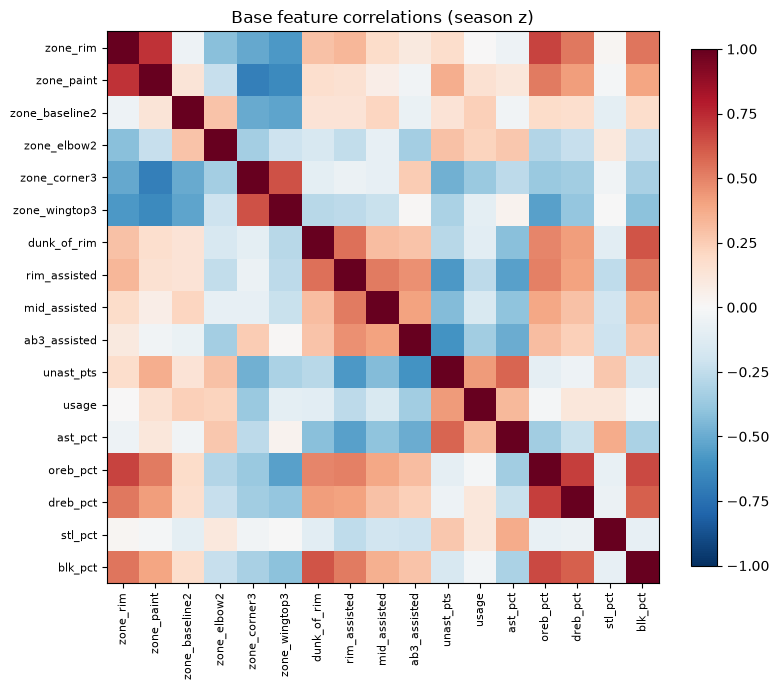

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(Cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(Cm))); ax.set_xticklabels(Cm.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(Cm))); ax.set_yticklabels(Cm.columns, fontsize=8)
ax.set_title("Base feature correlations (season z)"); plt.colorbar(im, fraction=.04); plt.tight_layout()

## Sanity: do the base features follow the player?
Next-season correlation for stayers vs transfers. Anything with move/stay well under ~0.8 is team-driven and shouldn't define an archetype.

In [8]:
mm = meta[["Player ID", "Season", "Team ID"]].join(X[BASE]).sort_values(["Player ID", "Season"])
nxt = mm.groupby("Player ID").shift(-1); pair = nxt["Season"].notna()
moved = (mm.loc[pair, "Team ID"].values != nxt.loc[pair, "Team ID"].values)
rows = []
for c in BASE:
    a, b = mm.loc[pair, c].values, nxt.loc[pair, c].values.astype(float)
    rs, rm = np.corrcoef(a[~moved], b[~moved])[0, 1], np.corrcoef(a[moved], b[moved])[0, 1]
    rows.append({"feature": c, "r_stay": rs, "r_move": rm, "move/stay": rm / rs})
pers = pd.DataFrame(rows).sort_values("move/stay", ascending=False).round(2)
print(f"pairs: {pair.sum()}  moved: {moved.sum()}"); pers

pairs: 4377  moved: 1445


,feature,r_stay,r_move,move/stay
6,dunk_of_rim,0.83,0.82,0.98
16,blk_pct,0.85,0.82,0.96
13,oreb_pct,0.87,0.81,0.93
12,ast_pct,0.80,0.73,0.92
0,zone_rim,0.87,0.77,0.89
14,dreb_pct,0.82,0.72,0.88
5,zone_wingtop3,0.87,0.76,0.87
1,zone_paint,0.82,0.70,0.85
15,stl_pct,0.69,0.58,0.85
9,ab3_assisted,0.65,0.55,0.84


In [9]:
pd.to_pickle({"X": X, "raw": raw.loc[X.index], "meta": meta, "base": BASE, "candidates": list(C), "logged": LOGGED,
               "config": {"DROP_SEASONS": DROP_SEASONS, "MPG_FLOOR": MPG_FLOOR, "G_FLOOR": G_FLOOR, "WINSOR": WINSOR,
                          "derived_choice": choice}}, OUT)
print("saved", OUT, X.shape)

saved aa_features.pkl (9907, 22)
